# Ансамбли: цены автомобилей и random forest

Предобработка табличных данных, bagging, blending, stacking и подбор деревьев. Отдельный блок: собственный random forest на готовых sklearn-деревьях для классификации региона insurance.

Train/test split 80/20, `random_state=42`; для blending train дополнительно разделён 80/20 на base/meta. Заполнение пропусков и частоты редких категорий рассчитаны до split. Для строгой оценки их нужно перенести внутрь folds.

Совместная лабораторная работа с Кириллом Слепцовым.

[Методы и результаты](../docs/classic-ml.md) · [Источники](../PROVENANCE.md)

Данные о подержанных автомобилях в Великобритании. Target: цена; признаки включают год выпуска, пробег и характеристики двигателя.

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator
from sklearn.ensemble import (BaggingRegressor, GradientBoostingRegressor, RandomForestClassifier,
                              RandomForestRegressor, StackingRegressor)
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (accuracy_score, classification_report, f1_score,
                             mean_absolute_percentage_error, mean_squared_error)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

warnings.filterwarnings("ignore")


def calc_metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    return rmse, mape


In [2]:
REPO_DIR = Path.cwd()
if REPO_DIR.name == "notebooks":
    REPO_DIR = REPO_DIR.parent
CARS_CSV = Path(os.environ.get("USED_CARS_CSV", str(REPO_DIR / "data" / "used_cars_UK.csv"))).expanduser().resolve()
if not CARS_CSV.is_file():
    raise FileNotFoundError(f"Поместите used_cars_UK.csv по пути {CARS_CSV}; ссылка на файл — в PROVENANCE.md")


## 1. Подготовка данных


In [3]:
df = pd.read_csv(CARS_CSV)

cols_to_drop = ['Unnamed: 0', 'Service history', 'title']
df = df.drop(columns=[c for c in cols_to_drop if c in df.columns])

num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

if 'Previous Owners' in df.columns:
    df['Previous Owners'] = df['Previous Owners'].fillna(0)

num_fill_mean = [col for col in num_cols if col not in ['Previous Owners', 'Price']]
for col in num_fill_mean:
    df[col] = df[col].fillna(df[col].mean())

cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

rare_thresh = 0.01

for col in cat_cols:
    freq = df[col].value_counts(normalize=True)
    rare_cats = freq[freq < rare_thresh].index
    df[col] = df[col].replace(rare_cats, 'Other')

df = pd.get_dummies(df, columns=cat_cols, drop_first=False)

X = df.drop('Price', axis=1)
y = df['Price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train = X_train.reset_index(drop=True)
X_test  = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test  = y_test.reset_index(drop=True)


## 2. Бэггинг


In [4]:
bag_model = BaggingRegressor(random_state=42)
bag_model.fit(X_train, y_train)

y_pred = bag_model.predict(X_test)
rmse, mape = calc_metrics(y_test, y_pred)

print(f"RMSE: {rmse:.2f}")
print(f"MAPE: {mape:.2f}%")


RMSE: 1791.49
MAPE: 23.35%


### Подбор параметров бэггинга: GridSearchCV, 5 folds


In [5]:
base_tree = DecisionTreeRegressor(random_state=42)

bag = BaggingRegressor(
    estimator=base_tree,
    random_state=42
)

param_grid = {
    "n_estimators": [10, 25, 50, 100, 200],
    "max_features": [0.2, 0.5, 0.7, 1.0],
    "max_samples": [0.5, 0.75, 1.0],
    "estimator__max_depth": [4, 6, 8, 10, 20, None]  # Параметры базового дерева задаются через estimator__.
}

grid = GridSearchCV(
    estimator=bag,
    param_grid=param_grid,
    scoring="neg_mean_squared_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

print("Лучшие гиперпараметры:")
print(grid.best_params_)

best_cv_mse = -grid.best_score_
best_cv_rmse = np.sqrt(best_cv_mse)
print(f"Лучший CV RMSE: {best_cv_rmse:.2f}")

best_model = grid.best_estimator_
y_pred_best = best_model.predict(X_test)

test_rmse, test_mape = calc_metrics(y_test, y_pred_best)

print(f"Test RMSE: {test_rmse:.2f}")
print(f"Test MAPE: {test_mape:.2f}%")


Fitting 5 folds for each of 360 candidates, totalling 1800 fits
Лучшие гиперпараметры:
{'estimator__max_depth': 20, 'max_features': 0.7, 'max_samples': 0.5, 'n_estimators': 200}
Лучший CV RMSE: 1497.26
Test RMSE: 1794.78
Test MAPE: 25.19%


### Результат подбора бэггинга

360 конфигураций × 5 folds, 1800 обучений. Лучший CV RMSE: **1497,26**. На test базовый bagging получил **RMSE 1791,49, MAPE 23,35%**, настроенный: **1794,78 / 25,19%**. Подбор не улучшил test-метрики.

## 3. Базовые модели, блендинг и стекинг


In [12]:
results = {}

X_base_train, X_meta_train, y_base_train, y_meta_train = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

X_base_train = X_base_train.reset_index(drop=True)
X_meta_train = X_meta_train.reset_index(drop=True)
y_base_train = y_base_train.reset_index(drop=True)
y_meta_train = y_meta_train.reset_index(drop=True)

linreg_full = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])
linreg_full.fit(X_train, y_train)
y_pred_lin_full = linreg_full.predict(X_test)
results["Linear Regression"] = calc_metrics(y_test, y_pred_lin_full)

knn_full = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsRegressor(n_neighbors=5))
])
knn_full.fit(X_train, y_train)
y_pred_knn_full = knn_full.predict(X_test)
results["kNN (k=5)"] = calc_metrics(y_test, y_pred_knn_full)

tree_full = DecisionTreeRegressor(random_state=42)
tree_full.fit(X_train, y_train)
y_pred_tree_full = tree_full.predict(X_test)
results["Decision Tree"] = calc_metrics(y_test, y_pred_tree_full)

bagging = BaggingRegressor(random_state=42)
bagging.fit(X_train, y_train)
y_pred_bag = bagging.predict(X_test)
results["Bagging (default)"] = calc_metrics(y_test, y_pred_bag)

base_linreg = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

base_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsRegressor(n_neighbors=5))
])

base_tree = DecisionTreeRegressor(random_state=42)

base_linreg.fit(X_base_train, y_base_train)
base_knn.fit(X_base_train, y_base_train)
base_tree.fit(X_base_train, y_base_train)

meta_pred_lin_train = base_linreg.predict(X_meta_train)
meta_pred_knn_train = base_knn.predict(X_meta_train)
meta_pred_tree_train = base_tree.predict(X_meta_train)

X_meta_train_blend = pd.DataFrame({
    "linreg_pred": meta_pred_lin_train,
    "knn_pred": meta_pred_knn_train,
    "tree_pred": meta_pred_tree_train
})

meta_model_blend = LinearRegression()
meta_model_blend.fit(X_meta_train_blend, y_meta_train)

meta_pred_lin_test = base_linreg.predict(X_test)
meta_pred_knn_test = base_knn.predict(X_test)
meta_pred_tree_test = base_tree.predict(X_test)

X_meta_test = pd.DataFrame({
    "linreg_pred": meta_pred_lin_test,
    "knn_pred": meta_pred_knn_test,
    "tree_pred": meta_pred_tree_test
})

y_pred_blend = meta_model_blend.predict(X_meta_test)
results["Blending"] = calc_metrics(y_test, y_pred_blend)

estimators = [
    ("linreg", Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ])),
    ("knn", Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(n_neighbors=5))
    ])),
    ("tree", DecisionTreeRegressor(random_state=42))
]

stack_model = StackingRegressor(
    estimators=estimators,
    final_estimator=LinearRegression(),
    n_jobs=-1
)

stack_model.fit(X_train, y_train)
y_pred_stack = stack_model.predict(X_test)
results["Stacking"] = calc_metrics(y_test, y_pred_stack)

rows = []
for name, (rmse, mape) in results.items():
    rows.append({"Model": name, "RMSE": rmse, "MAPE (%)": mape})

results_df = pd.DataFrame(rows)
results_df = results_df.sort_values(by="RMSE")

print(results_df)


               Model         RMSE   MAPE (%)
3  Bagging (default)  1791.487463  23.347682
4           Blending  1979.437183  28.632374
5           Stacking  1984.191515  26.608568
0  Linear Regression  2258.916434  35.713600
2      Decision Tree  2269.761821  31.825903
1          kNN (k=5)  2291.323648  27.810170


### Стекинг с бэггингом среди базовых моделей


In [13]:
linreg_base = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

knn_base = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsRegressor(n_neighbors=5))
])

tree_base = DecisionTreeRegressor(random_state=42)

bagging_base = BaggingRegressor(
    estimator=DecisionTreeRegressor(max_depth=20, random_state=42),
    n_estimators=200,
    max_features=0.7,
    max_samples=0.5,
    random_state=42
)

estimators_ext = [
    ("linreg", linreg_base),
    ("knn", knn_base),
    ("tree", tree_base),
    ("bagging", bagging_base)
]

stack_with_bagging = StackingRegressor(
    estimators=estimators_ext,
    final_estimator=LinearRegression(),
    n_jobs=-1
)

stack_with_bagging.fit(X_train, y_train)

y_pred_stack_bag = stack_with_bagging.predict(X_test)
rmse_stack_bag, mape_stack_bag = calc_metrics(y_test, y_pred_stack_bag)

print(f"Stacking + Bagging - RMSE: {rmse_stack_bag:.2f}")
print(f"Stacking + Bagging - MAPE: {mape_stack_bag:.2f}%")


Stacking + Bagging - RMSE: 1767.68
Stacking + Bagging - MAPE: 23.69%


### Подбор дерева и применение в стекинге


In [14]:
tree = DecisionTreeRegressor(random_state=42)

param_grid = {
    "max_depth": [4, 6, 8, 10, 15, 20, None],
    "min_samples_split": [2, 5, 10, 20],
    "max_features": [None, "sqrt", "log2", 0.5, 0.7, 1.0]
}

grid_tree = GridSearchCV(
    estimator=tree,
    param_grid=param_grid,
    scoring="neg_mean_squared_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_tree.fit(X_train, y_train)

print("Лучшие параметры дерева:")
print(grid_tree.best_params_)

best_tree = grid_tree.best_estimator_

tree_default = DecisionTreeRegressor(random_state=42)
tree_default.fit(X_train, y_train)
y_pred_tree_def = tree_default.predict(X_test)
rmse_tree_def, mape_tree_def = calc_metrics(y_test, y_pred_tree_def)

y_pred_tree_best = best_tree.predict(X_test)
rmse_tree_best, mape_tree_best = calc_metrics(y_test, y_pred_tree_best)

print("\nКачество одиночного дерева:")
print(f"  Default tree   RMSE: {rmse_tree_def:.2f}, MAPE: {mape_tree_def:.2f}%")
print(f"  Tuned tree     RMSE: {rmse_tree_best:.2f}, MAPE: {mape_tree_best:.2f}%")
print(f"  Δ RMSE: {rmse_tree_def - rmse_tree_best:.2f}")
print(f"  Δ MAPE: {mape_tree_def - mape_tree_best:.2f} п.п.\n")

estimators_default = [
    ("linreg", Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ])),
    ("knn", Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(n_neighbors=5))
    ])),
    ("tree", DecisionTreeRegressor(random_state=42))
]

stack_default = StackingRegressor(
    estimators=estimators_default,
    final_estimator=LinearRegression(),
    n_jobs=-1
)

stack_default.fit(X_train, y_train)
y_pred_stack_def = stack_default.predict(X_test)
rmse_stack_def, mape_stack_def = calc_metrics(y_test, y_pred_stack_def)

estimators_tuned = [
    ("linreg", Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ])),
    ("knn", Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(n_neighbors=5))
    ])),
    ("tree", best_tree)
]

stack_tuned = StackingRegressor(
    estimators=estimators_tuned,
    final_estimator=LinearRegression(),
    n_jobs=-1
)

stack_tuned.fit(X_train, y_train)
y_pred_stack_tuned = stack_tuned.predict(X_test)
rmse_stack_tuned, mape_stack_tuned = calc_metrics(y_test, y_pred_stack_tuned)

print("Качество стекинга:")
print(f"  Stacking (default tree) RMSE: {rmse_stack_def:.2f}, MAPE: {mape_stack_def:.2f}%")
print(f"  Stacking (tuned tree)   RMSE: {rmse_stack_tuned:.2f}, MAPE: {mape_stack_tuned:.2f}%")
print(f"  Δ RMSE: {rmse_stack_def - rmse_stack_tuned:.2f}")
print(f"  Δ MAPE: {mape_stack_def - mape_stack_tuned:.2f} п.п.")


Fitting 5 folds for each of 168 candidates, totalling 840 fits
Лучшие параметры дерева:
{'max_depth': 8, 'max_features': None, 'min_samples_split': 20}

Качество одиночного дерева:
  Default tree   RMSE: 2269.76, MAPE: 31.83%
  Tuned tree     RMSE: 1979.10, MAPE: 30.05%
  Δ RMSE: 290.67
  Δ MAPE: 1.77 п.п.

Качество стекинга:
  Stacking (default tree) RMSE: 1984.19, MAPE: 26.61%
  Stacking (tuned tree)   RMSE: 1887.47, MAPE: 25.62%
  Δ RMSE: 96.72
  Δ MAPE: 0.99 п.п.


### Результат подбора дерева

Настроенное дерево: test RMSE **1979,10**, MAPE **30,05%**; базовое: **2269,76 / 31,83%**. Замена дерева в stacking дала **1887,47 / 25,62%** вместо **1984,19 / 26,61%**. Все сравнения используют один test.

### Сравнение метамоделей: linear regression, random forest и gradient boosting


In [15]:
estimators_tuned = [
    ("linreg", Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ])),
    ("knn", Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(n_neighbors=5))
    ])),
    ("tree", best_tree)
]

meta_models = {
    "LinearRegression": LinearRegression(),
    "RandomForest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ),
    "GradientBoosting": GradientBoostingRegressor(
        n_estimators=200,
        random_state=42
    )
}

results = []

for name, meta in meta_models.items():
    stack_model = StackingRegressor(
        estimators=estimators_tuned,
        final_estimator=meta,
        n_jobs=-1
    )

    stack_model.fit(X_train, y_train)
    y_pred_stack = stack_model.predict(X_test)
    rmse, mape = calc_metrics(y_test, y_pred_stack)

    results.append({"Meta-model": name, "RMSE": rmse, "MAPE (%)": mape})

results_df = pd.DataFrame(results).sort_values(by="RMSE")
print(results_df)


         Meta-model         RMSE   MAPE (%)
2  GradientBoosting  1775.053351  25.517011
1      RandomForest  1782.412664  25.307326
0  LinearRegression  1887.472098  25.615602


## 4. Собственный random forest: классификация региона в insurance


Первые строки:
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520 

Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Описательная статистика числовых признаков:
             

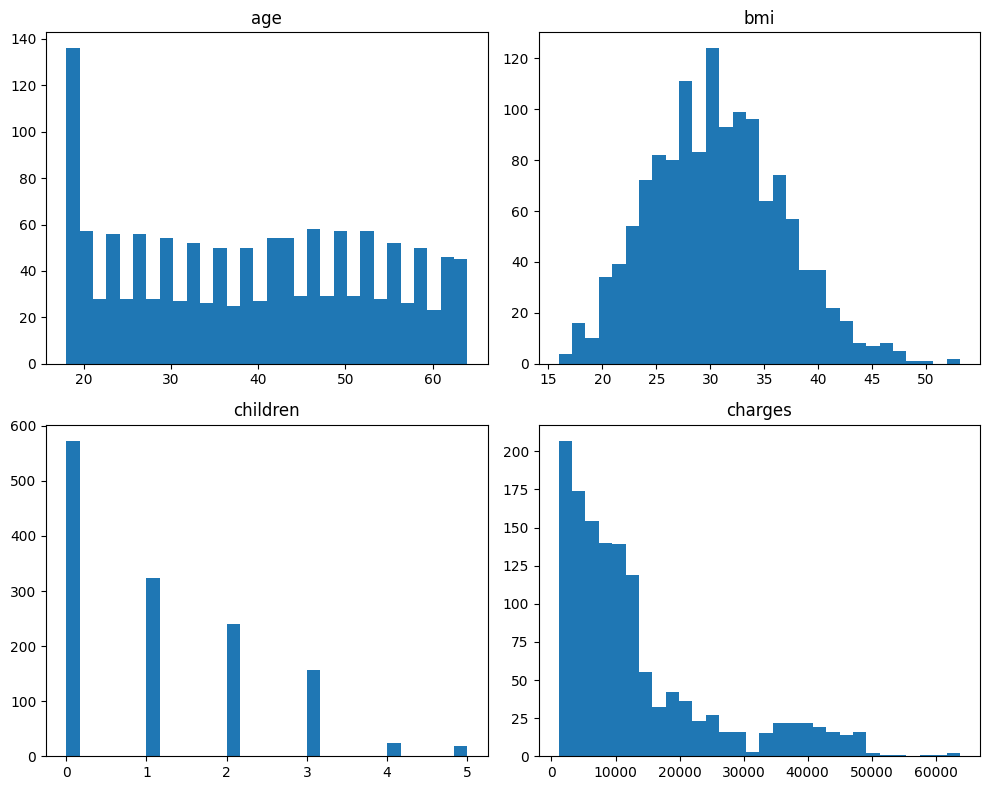

Корреляции числовых признаков:
               age       bmi  children   charges
age       1.000000  0.109344  0.041536  0.298308
bmi       0.109344  1.000000  0.012755  0.198401
children  0.041536  0.012755  1.000000  0.067389
charges   0.298308  0.198401  0.067389  1.000000 

Пропуски после заполнения:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64 

Описательная статистика после IQR-клиппинга:
               age          bmi     children       charges
count  1337.000000  1337.000000  1337.000000   1337.000000
mean     39.222139    30.650247     1.095737  12491.159952
std      14.044333     6.059655     1.205571  10165.511950
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.290000     0.000000   4746.344000
50%      39.000000    30.400000     1.000000   9386.161300
75%      51.000000    34.700000     2.000000  16657.717450
max      64.000000    47.315000     5.000000  34524.777625 



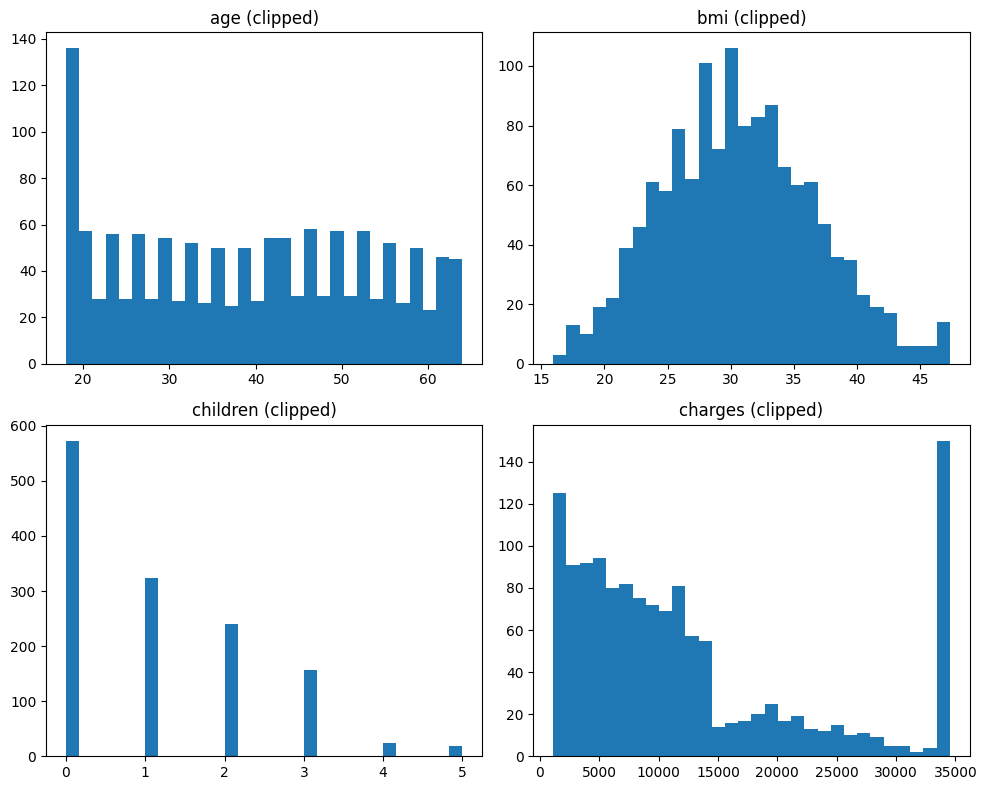

Форма X: (1337, 6)
Форма y: (1337,)
Столбцы X после кодирования:
['age', 'bmi', 'children', 'charges', 'sex_male', 'smoker_yes']


In [19]:
url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
df = pd.read_csv(url)

print("Первые строки:")
print(df.head(), "\n")

print("Информация о данных:")
df.info()
print()

print("Описательная статистика числовых признаков:")
print(df.describe(), "\n")

print("Число пропусков по столбцам:")
print(df.isna().sum(), "\n")

print("Число дубликатов:", df.duplicated().sum(), "\n")

df = df.drop_duplicates().reset_index(drop=True)
print("Форма после удаления дубликатов:", df.shape, "\n")

numeric_cols = ["age", "bmi", "children", "charges"]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

for i, col in enumerate(numeric_cols):
    axes[i].hist(df[col], bins=30)
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

print("Корреляции числовых признаков:")
print(df[numeric_cols].corr(), "\n")

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Пропуски после заполнения:")
print(df.isna().sum(), "\n")

def clip_outliers_iqr(series, factor=1.5):
    """Клиппинг выбросов по IQR: [Q1 - factor*IQR, Q3 + factor*IQR]."""
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - factor * iqr
    upper = q3 + factor * iqr
    return series.clip(lower=lower, upper=upper)

df_out = df.copy()
for col in numeric_cols:
    df_out[col] = clip_outliers_iqr(df_out[col], factor=1.5)

print("Описательная статистика после IQR-клиппинга:")
print(df_out[numeric_cols].describe(), "\n")

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

for i, col in enumerate(numeric_cols):
    axes[i].hist(df_out[col], bins=30)
    axes[i].set_title(col + " (clipped)")

plt.tight_layout()
plt.show()

y = df_out["region"]
X = df_out.drop(columns=["region"])

X = pd.get_dummies(X, drop_first=True)

print("Форма X:", X.shape)
print("Форма y:", y.shape)
print("Столбцы X после кодирования:")
print(X.columns.tolist())


### Сравнение собственной реализации и sklearn


In [20]:
url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
df = pd.read_csv(url)

df = df.drop_duplicates().reset_index(drop=True)

numeric_cols = ["age", "bmi", "children", "charges"]

for col in numeric_cols:
    df[col] = clip_outliers_iqr(df[col], factor=1.5)

y = df["region"]
X = df.drop(columns=["region"])

X = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

class MyRandomForest(BaseEstimator):
    """
    Простейшая реализация Random Forest для задачи классификации.
    Использует:
    - бутстрэп по объектам
    - случайный поднабор признаков max_features
    - критерий 'gini' как функцию потерь в деревьях
    """

    def __init__(
        self,
        n_estimators=100,
        *,
        max_features="sqrt",
        min_samples_split=2,
        min_samples_leaf=1,
        max_depth=None,
        bootstrap=True,
        random_state=None,
        criterion="gini"
    ):
        self.n_estimators = n_estimators
        self.max_features = max_features
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.max_depth = max_depth
        self.bootstrap = bootstrap
        self.random_state = random_state
        self.criterion = criterion

        self.estimators_ = []
        self.classes_ = None
        self.n_classes_ = None

    def _bootstrap_sample(self, X, y, rng):
        n_samples = X.shape[0]
        indices = rng.randint(0, n_samples, size=n_samples)
        return X[indices], y[indices]

    def fit(self, X_train, y_train):
        X = np.asarray(X_train)
        y = np.asarray(y_train)

        self.classes_, y_encoded = np.unique(y, return_inverse=True)
        self.n_classes_ = len(self.classes_)

        rng = np.random.RandomState(self.random_state)
        self.estimators_ = []

        for i in range(self.n_estimators):
            # Bootstrap по объектам.
            if self.bootstrap:
                X_boot, y_boot = self._bootstrap_sample(X, y_encoded, rng)
            else:
                X_boot, y_boot = X, y_encoded

            tree_random_state = rng.randint(0, 10**9)

            tree = DecisionTreeClassifier(
                criterion=self.criterion,
                max_depth=self.max_depth,
                min_samples_split=self.min_samples_split,
                min_samples_leaf=self.min_samples_leaf,
                max_features=self.max_features,
                random_state=tree_random_state
            )
            tree.fit(X_boot, y_boot)
            self.estimators_.append(tree)

        return self

    def predict_proba(self, X_test):
        if not self.estimators_:
            raise ValueError("Модель ещё не обучена. Сначала вызовите fit().")

        X = np.asarray(X_test)
        n_samples = X.shape[0]
        proba_sum = np.zeros((n_samples, self.n_classes_), dtype=float)

        for tree in self.estimators_:
            proba = tree.predict_proba(X)
            proba_sum += proba

        proba_avg = proba_sum / len(self.estimators_)
        return proba_avg

    def predict(self, X_test):
        proba = self.predict_proba(X_test)
        class_indices = np.argmax(proba, axis=1)
        return self.classes_[class_indices]

rf_sklearn = RandomForestClassifier(random_state=42)
rf_sklearn.fit(X_train, y_train)

y_pred_sklearn = rf_sklearn.predict(X_test)

rf_my = MyRandomForest(
    n_estimators=100,
    max_features="sqrt",
    min_samples_split=2,
    min_samples_leaf=1,
    max_depth=None,
    bootstrap=True,
    random_state=42,
    criterion="gini"
)
rf_my.fit(X_train, y_train)

y_pred_my = rf_my.predict(X_test)

def evaluate_model(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    print(f"{name}")
    print(f"  Accuracy: {acc:.4f}")
    print(f"  Macro F1: {macro_f1:.4f}")
    print()

    return acc, macro_f1

print("=== КАЧЕСТВО МОДЕЛЕЙ НА ТЕСТЕ ===")
acc_sklearn, f1_sklearn = evaluate_model("Sklearn RandomForest", y_test, y_pred_sklearn)
acc_my, f1_my = evaluate_model("MyRandomForest", y_test, y_pred_my)

results_df = pd.DataFrame({
    "Model": ["Sklearn RF", "My RF"],
    "Accuracy": [acc_sklearn, acc_my],
    "Macro F1": [f1_sklearn, f1_my]
})
print(results_df)

print("\n=== Classification report: Sklearn RF ===")
print(classification_report(y_test, y_pred_sklearn))

print("\n=== Classification report: My RF ===")
print(classification_report(y_test, y_pred_my))


Train shape: (1069, 6)  Test shape: (268, 6)
=== КАЧЕСТВО МОДЕЛЕЙ НА ТЕСТЕ ===
Sklearn RandomForest
  Accuracy: 0.3843
  Macro F1: 0.3787

MyRandomForest
  Accuracy: 0.3955
  Macro F1: 0.3867

        Model  Accuracy  Macro F1
0  Sklearn RF  0.384328  0.378745
1       My RF  0.395522  0.386674

=== Classification report: Sklearn RF ===
              precision    recall  f1-score   support

   northeast       0.38      0.40      0.39        65
   northwest       0.40      0.42      0.41        65
   southeast       0.47      0.48      0.47        73
   southwest       0.27      0.23      0.25        65

    accuracy                           0.38       268
   macro avg       0.38      0.38      0.38       268
weighted avg       0.38      0.38      0.38       268


=== Classification report: My RF ===
              precision    recall  f1-score   support

   northeast       0.37      0.40      0.38        65
   northwest       0.40      0.38      0.39        65
   southeast       0.49   

### Результат random forest

После удаления дубликата: 1337 строк, стратифицированное разбиение с seed 42 на 1069 train и 268 test. sklearn RF: accuracy **0,3843**, macro-F1 **0,3787**; собственный RF: **0,3955 / 0,3867**.

Ансамбль использует `DecisionTreeClassifier`, bootstrap и усреднение вероятностей. IQR-клиппинг рассчитан до split. Небольшая разница на одном test не позволяет выбрать лучший метод.